# Trabalho Prático: Deep Q-Network no Lunar Lander
# Aprendizado por Reforço 2025/1

#### Lucas Almeida Santos de Souza - 2021092563
#### Thaís Ferreira da Silva - 2021092571

Este notebook contém a implementação das tarefas 3.1, 3.2 e 3.3 especificadas no documento do trabalho prático.

- **Tarefa 3.1:** Implementação de um agente Deep Q-Network (DQN) a partir do zero.
- **Tarefa 3.2:** Estrutura para a busca de hiperparâmetros e treinamento do agente.
- **Tarefa 3.3:** Comparação do desempenho do agente implementado com a versão de referência da biblioteca Stable Baselines3.

In [14]:
# Bibliotecas padrão
import os # Para manipulação de arquivos e diretórios
import time
import random
from collections import deque, namedtuple # Para armazenar a memória de replay
from itertools import product # Para gerar combinações de hiperparâmetros

# Bibliotecas de terceiros
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm # Para mostrar o progresso do loop

# PyTorch para Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

# Gymnasium para ambientes de RL
import gymnasium as gym

# Stable Baselines3 para comparação
from stable_baselines3 import DQN
from stable_baselines3.common.evaluation import evaluate_policy


___

## Tarefa 3.1: Implementar um Deep Q-Network

Nesta seção, implementamos os componentes essenciais do algoritmo DQN, conforme solicitado.  Isso inclui:
- **`QNetwork`**: A rede neural que aprende a aproximar a função Q(s, a).
- **`ReplayBuffer`**: Uma estrutura de dados para armazenar e amostrar experiências, quebrando a correlação entre amostras sequenciais.
- **`DQNAgent`**: A classe principal que encapsula a lógica do agente, incluindo a política ε-greedy, o processo de aprendizagem e a atualização da rede alvo.

In [ ]:
class ReplayBuffer:
    def __init__(self, capacity, state_dim, action_dim, seed=42):
        self.buffer = deque(maxlen=capacity)    # Memória de replay
        self.state_dim = state_dim              # Dimensão do espaço de estados
        self.action_dim = action_dim            # Dimensão do espaço de ações

        random.seed(seed)
        np.random.seed(seed)

    def push(self, state, action, reward, next_state, done):
        """
        Armazena uma transição na memória de replay.
        """
        
        self.buffer.append((state, action, reward, next_state, done))

    def sample(self, batch_size: int):
        """
        Amostra um batch aleatório da memória de replay.
        Retorna tensores PyTorch para estados, ações, recompensas, próximos estados e done flags.
        """

        # Verifica se há transições suficientes na memória
        if len(self.buffer) < batch_size:
            return None, None, None, None, None

        state, action, reward, next_state, done = zip(*random.sample(self.buffer, batch_size))

        return (torch.from_numpy(np.array(state)).float(),
                torch.from_numpy(np.array(action)).long(),
                torch.from_numpy(np.array(reward)).float(),
                torch.from_numpy(np.array(next_state)).float(),
                torch.from_numpy(np.array(done)).float())


    def __len__(self):
        return len(self.buffer)

In [ ]:
class DQN(nn.Module):
    def __init__(self, input_dim: int, output_dim: int, hidden_dim: int = 64):
        """
        Args:
            input_dim: dimensão do vetor de estado (entrada)
            output_dim: número de ações possíveis (saída)
            hidden_dim: tamanho das camadas ocultas
        """
        
        super(DQN, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)      # Primeira camada totalmente conectada
        self.fc2 = nn.Linear(hidden_dim, hidden_dim)     # Segunda camada totalmente conectada
        self.fc3 = nn.Linear(hidden_dim, output_dim)     # Camada de saída

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        Propagação para frente: aplica ReLU nas camadas ocultas.
        """

        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x

In [ ]:
class DQNAgent:
    def __init__(self, state_dim: int, action_dim: int, hidden_dim: int, learning_rate: float, gamma: float,
                 epsilon_start: float, epsilon_end: float, epsilon_decay: float, target_update_freq: int,
                 buffer_capacity: int, batch_size: int):
        """
        Args:
            state_dim: dimensão do vetor de estado
            action_dim: número de ações possíveis
            hidden_dim: tamanho das camadas ocultas da rede neural
            learning_rate: taxa de aprendizado do otimizador
            gamma: fator de desconto para recompensas futuras
            epsilon_start: valor inicial de epsilon para exploração
            epsilon_end: valor final de epsilon para exploração
            epsilon_decay: taxa de decaimento de epsilon
            target_update_freq: frequência de atualização da rede alvo
            buffer_capacity: capacidade máxima da memória de replay
            batch_size: tamanho do batch para atualização da rede
        """
        
        self.state_dim = state_dim
        self.action_dim = action_dim

        self.policy_net = DQN(state_dim, action_dim, hidden_dim) # Inicializa a rede neural de política
        self.target_net = DQN(state_dim, action_dim, hidden_dim) # Inicializa a rede neural alvo
        self.target_net.load_state_dict(self.policy_net.state_dict())
        self.target_net.eval()

        # Inicializa otimizador Adam para atualizar os pesos da rede
        self.optimizer = optim.Adam(self.policy_net.parameters(), lr=learning_rate)
        self.criterion = nn.MSELoss()

        self.gamma = gamma
        self.epsilon = epsilon_start
        self.epsilon_end = epsilon_end
        self.epsilon_decay = epsilon_decay

        self.target_update_freq = target_update_freq
        self.update_count = 0

        self.replay_buffer = ReplayBuffer(buffer_capacity, state_dim, action_dim)
        self.batch_size = batch_size

    def select_action(self, state: np.ndarray) -> int:
        """
        Seleciona uma ação com base na política epsilon-greedy.
        Args:
            state: vetor de estado atual
        """

        state = torch.from_numpy(state).float().unsqueeze(0)
        
        self.epsilon = max(self.epsilon_end, self.epsilon - self.epsilon_decay)
        
        if random.random() < self.epsilon:
            return random.randrange(self.action_dim) # Ação aleatória (exploração)
        else:
            with torch.no_grad(): # Desativa o cálculo de gradientes para eficiência
                q_values = self.policy_net(state)
                return q_values.argmax().item() # Ação com maior Q-value (exploitação)

    def update_model(self):
        """
        Atualiza os pesos da rede neural usando um batch da memória de replay.
        """

        # Não atualiza o modelo se não houver transições suficientes na memória de replay
        if len(self.replay_buffer) < self.batch_size:
            return

        states, actions, rewards, next_states, dones = self.replay_buffer.sample(self.batch_size)

        actions = actions.unsqueeze(1)
        rewards = rewards.unsqueeze(1)
        dones = dones.unsqueeze(1)

        current_q_values = self.policy_net(states).gather(1, actions)

        with torch.no_grad(): # Desativa o cálculo de gradientes para eficiência
            # Calcula os Q-valores da rede alvo para os próximos estados
            next_q_values_target = self.target_net(next_states)
            max_next_q_values = next_q_values_target.max(1)[0].unsqueeze(1)
            
            target_q_values = rewards + (1 - dones) * self.gamma * max_next_q_values

        loss = self.criterion(current_q_values, target_q_values)

        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

        self.update_count += 1

        # Atualiza a rede alvo periodicamente
        if self.update_count % self.target_update_freq == 0:
            self.target_net.load_state_dict(self.policy_net.state_dict())
            self.target_net.eval()

    def train(self, env: gym.Env, num_episodes: int, name: str) -> list:
        """
        Treina o agente DQN.
        Args:
            env: ambiente Gymnasium
            num_episodes: número de episódios para treinar
            name: nome do modelo para exibição
        """
        
        episode_rewards = []
        
        for episode in (pbar := tqdm(range(1, num_episodes + 1))):
            state, _ = env.reset()
            done = False
            total_reward = 0
            
            while not done:
                action = self.select_action(state)
                next_state, reward, terminated, truncated, _ = env.step(action)
                done = terminated or truncated

                # Armazena a transição na memória de replay
                self.replay_buffer.push(state, action, reward, next_state, done)
                
                state = next_state
                total_reward += reward

                if len(self.replay_buffer) >= self.batch_size:
                    self.update_model()

            episode_rewards.append(total_reward)
            
            pbar.set_postfix(Recompensa=f'{total_reward:.2f}', Model=f'{name}')

        env.close()
        return episode_rewards

    def save_model(self, path: str):
        """
        Salva os pesos da rede neural de política em um arquivo.
        """
        
        torch.save(self.policy_net.state_dict(), path)

___
## Tarefa 3.2: Realizar a Busca de Hiperparâmetros

Com a implementação do DQN concluída, o próximo passo é treinar o agente e buscar uma combinação eficaz de hiperparâmetros para maximizar seu desempenho.

Abaixo, definimos um conjunto inicial de hiperparâmetros. A função `train_dqn` e a classe `DQNAgent` foram estruturadas para permitir a fácil alteração desses valores. O processo de busca envolveria a execução de múltiplos treinamentos com diferentes configurações e a comparação dos resultados (por exemplo, a pontuação média final, a velocidade de convergência, etc.).

Para este notebook, vamos executar um único treinamento com uma configuração base bem-sucedida.

In [ ]:
def generate_hyperparameter_combinations(param_grid: dict) -> list:
    """
    Gera todas as combinações possíveis de hiperparâmetros a partir de um dicionário.
    Args:
        param_grid: dicionário que mapeia nomes dos hiperparâmetros em listas de valores possíveis
    """

    keys = param_grid.keys()
    values = [param_grid[key] for key in keys]
    combinations_raw = product(*values)
    combinations = [dict(zip(keys, v)) for v in combinations_raw]
    return combinations

In [9]:
STATE_DIM = 8
ACTION_DIM = 4

param_grid = {
    'learning_rate': [0.001],                       # Taxa de aprendizado
    'gamma': [0.99],                                # Fator de desconto
    'hidden_dim': [8, 16],                          # Dimensão das camadas ocultas da rede
    'buffer_capacity': [5000],                      # Tamanho do replay buffer
    'batch_size': [8, 16],                          # Tamanho do batch
    'target_update_freq': [25, 200, 500],           # Frequência de atualização da rede alvo
    'epsilon_start': [1.0],                         # Valor inicial de epsilon (geralmente fixo em 1.0)
    'epsilon_end': [0.1],                           # Valor final de epsilon
    'num_episodes': [150, 300, 450]                 # Número de episódios de treinamento
}


In [ ]:
results = {}

best_my_dqn_avg_reward = -np.inf 
best_my_dqn_std_reward = 0.0 
best_my_dqn_rewards = [] 
best_my_dqn_params = {}

top_10_models = []

MODEL_SAVE_DIR = "dqn_models" 
os.makedirs(MODEL_SAVE_DIR, exist_ok=True) 

combinations = generate_hyperparameter_combinations(param_grid)

print(f"Total de combinações a serem testadas: {len(combinations)}\n")

# Treina o agente DQN com todas as combinações de hiperparâmetros e salva os resultados
# Mantém os 10 melhores modelos com base na média das recompensas dos últimos 100
for i, params_original in enumerate(combinations): 

    model_filename = "_".join([f"{k}{str(v).replace('.', 'p')}" for k, v in params_original.items()])

    config_name = f"config_{i+1}-model_{model_filename}"
    
    params = params_original.copy()
    num_episodes_for_train = params.pop('num_episodes') 
    params['epsilon_decay'] = (params['epsilon_start'] - params['epsilon_end']) / num_episodes_for_train

    env = gym.make("LunarLander-v3")
    current_agent = DQNAgent( 
        state_dim=STATE_DIM,
        action_dim=ACTION_DIM,
        **params
    )

    rewards = current_agent.train(env, num_episodes_for_train, f'config_{i+1}-model_{model_filename}')
    results[config_name] = rewards

    avg_reward_last_100 = np.mean(rewards[-100:]) if len(rewards) >= 100 else np.mean(rewards)

    if len(top_10_models) < 10:
        top_10_models.append((avg_reward_last_100, params_original.copy(), rewards))
        top_10_models.sort(key=lambda x: x[0], reverse=True) # Manter em ordem decrescente de recompensa
    else:
        if avg_reward_last_100 > top_10_models[-1][0]:
            top_10_models.pop()
            top_10_models.append((avg_reward_last_100, params_original.copy(), rewards))
            top_10_models.sort(key=lambda x: x[0], reverse=True)
    
    model_path = os.path.join(MODEL_SAVE_DIR, f"config_{i+1}-model_{model_filename}.pth")
    current_agent.save_model(model_path)

    if avg_reward_last_100 > best_my_dqn_avg_reward:
        best_my_dqn_avg_reward = avg_reward_last_100
        best_my_dqn_params = params_original.copy()
        best_my_dqn_std_reward = np.std(rewards[-100:]) if len(rewards) >= 100 else np.std(rewards)
        best_my_dqn_rewards = rewards 
        
    env.close()

Total de combinações a serem testadas: 36



100%|██████████| 450/450 [03:58<00:00,  1.88it/s, Model=config_36-model_learning_rate0p001_gamma0p99_hidden_dim16_buffer_capacity5000_batch_size16_target_update_freq500_epsilon_start1p0_epsilon_end0p1_num_episodes450, Recompensa=261.95] 


In [ ]:
def moving_average_manual(data: list, window_size: int) -> list:
    """
    Calcula a média móvel de uma lista de dados com uma janela fixa.
    Args:
        data: lista de dados
        window_size: tamanho da janela para calcular a média móvel
    """
    
    smoothed = []
    for i in range(len(data) - window_size + 1):
        window = data[i:i+window_size]
        average = sum(window) / window_size
        smoothed.append(average)
    return smoothed

/tmp/ipykernel_1589/2528161728.py:15: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout(rect=[0, 1, 1.1, 1])


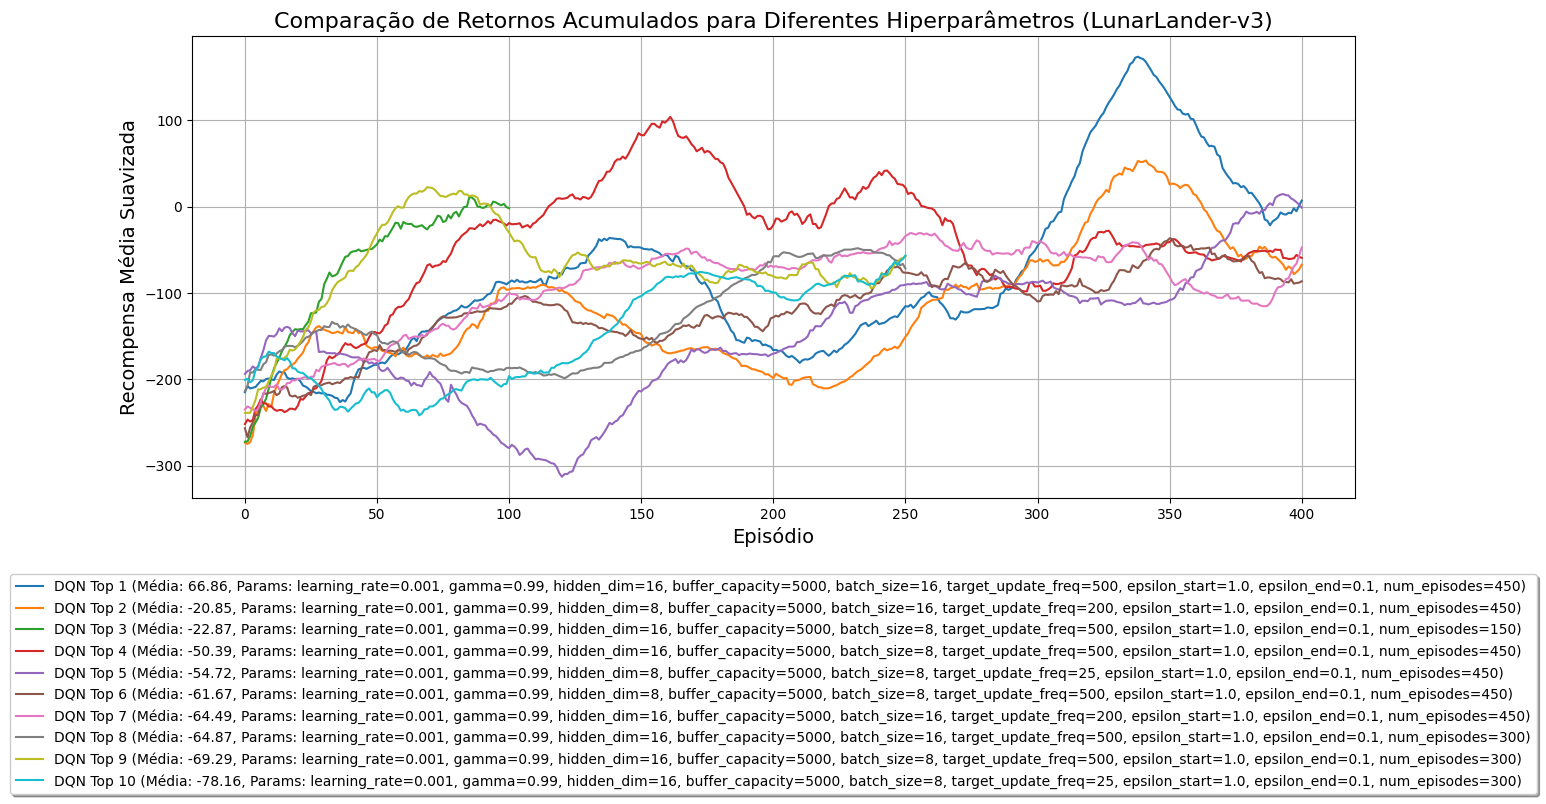

In [12]:
plt.figure(figsize=(15, 6))

for i, (mean_reward, params, rewards_history) in enumerate(top_10_models):
    smoothed_rewards = moving_average_manual(rewards_history, 50)
    param_str = ", ".join([f"{k}={v}" for k, v in params.items()])
    plt.plot(smoothed_rewards, label=f'DQN Top {i+1} (Média: {mean_reward:.2f}, Params: {param_str})')


plt.title('Comparação de Retornos Acumulados para Diferentes Hiperparâmetros (LunarLander-v3)', fontsize=16)
plt.xlabel('Episódio', fontsize=14)
plt.ylabel('Recompensa Média Suavizada', fontsize=14)
plt.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.15),
           fancybox=True, shadow=True, ncol=1)
plt.grid(True)
plt.tight_layout(rect=[0, 1, 1.1, 1])
plt.show()


___
## Tarefa 3.3: Comparação com o Stable Baselines3

Para validar nossa implementação, comparamos seu desempenho com a versão do DQN fornecida pela biblioteca Stable Baselines3 (SB3).  Treinamos um agente SB3 com sua configuração padrão no mesmo ambiente e depois avaliamos ambos os agentes em 100 episódios para obter uma medida de desempenho robusta.

In [15]:
env_sb3 = gym.make("LunarLander-v3")
model_sb3 = DQN("MlpPolicy", env_sb3, verbose=0) 
model_sb3.learn(total_timesteps=20_000)

mean_reward_sb3, std_reward_sb3 = evaluate_policy(model_sb3, env_sb3, n_eval_episodes=100)
env_sb3.close()

/home/thaiswsl/.local/lib/python3.10/site-packages/stable_baselines3/common/evaluation.py:67: UserWarning: Evaluation environment is not wrapped with a ``Monitor`` wrapper. This may result in reporting modified episode lengths and rewards, if other wrappers happen to modify these. Consider wrapping environment first with ``Monitor`` wrapper.
  warnings.warn(


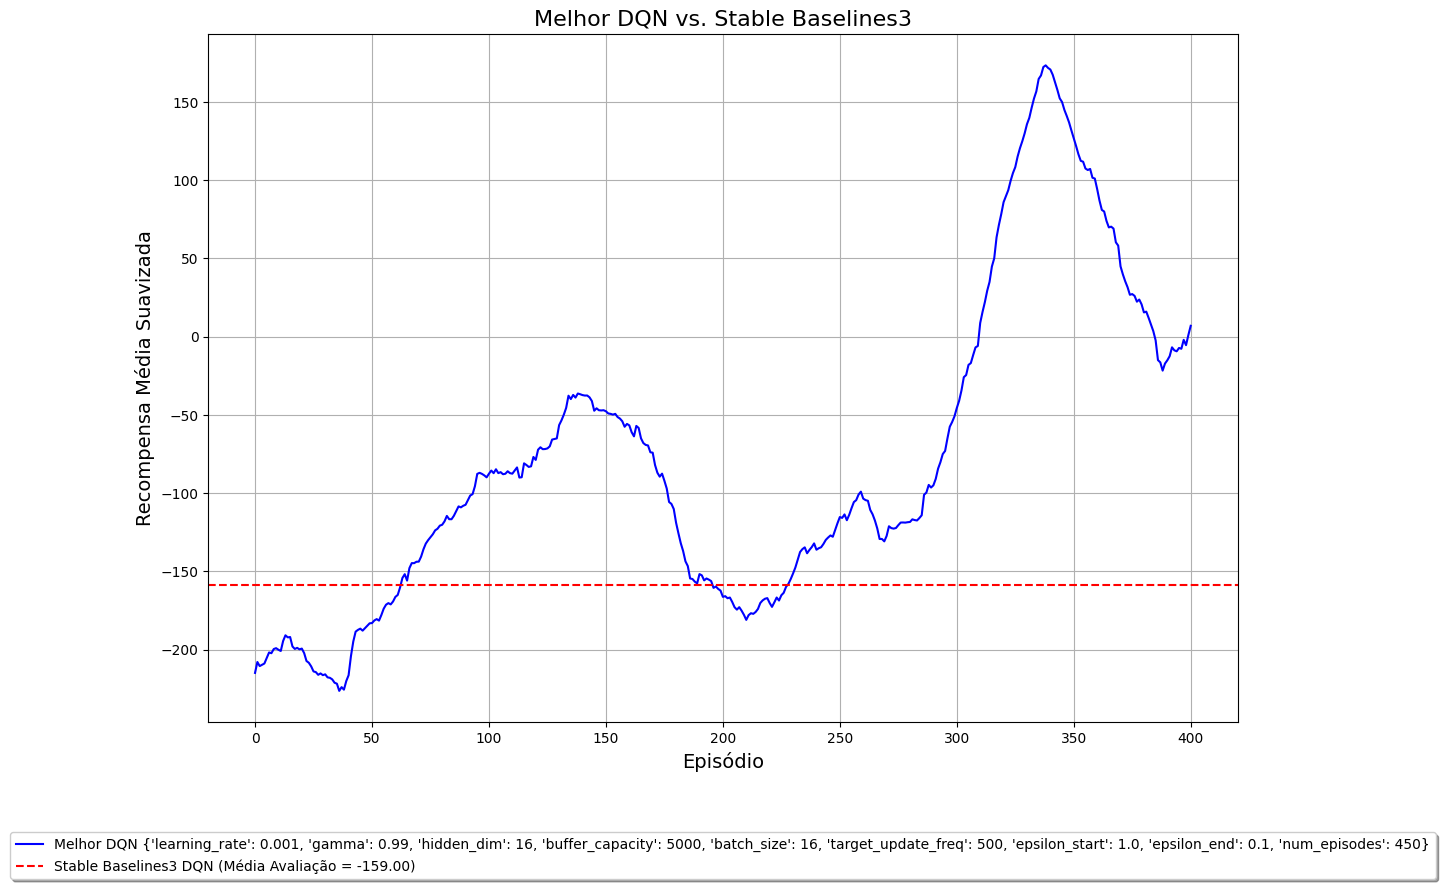

In [16]:
plt.figure(figsize=(14, 9))

num_episodes_best_dqn = len(best_my_dqn_rewards)
smoothed_best_rewards = moving_average_manual(rewards, 50)

plt.plot(smoothed_best_rewards, label=f'Melhor DQN {best_my_dqn_params}', color='blue')

plt.axhline(y=mean_reward_sb3, color='red', linestyle='--', label=f'Stable Baselines3 DQN (Média Avaliação = {mean_reward_sb3:.2f})')

plt.title('Melhor DQN vs. Stable Baselines3', fontsize=16)
plt.xlabel('Episódio', fontsize=14)
plt.ylabel('Recompensa Média Suavizada', fontsize=14)
plt.legend(fontsize=10, loc='upper center', bbox_to_anchor=(0.5, -0.15),
           fancybox=True, shadow=True, ncol=1)
plt.grid(True)
plt.tight_layout()
plt.show()

___
## Visualização do Modelo

(remova o comentário da última linha para rodar)

In [ ]:
# --- CONFIGURAÇÃO MANUAL DO MODELO A SER RODADO ---
MODEL_PATH = "dqn_models/best_dqn_model.pth"
HIDDEN_DIM_OF_MODEL = 16 

def run_simulation():
    """
    Executa a simulação do modelo DQN treinado no ambiente LunarLander-v3.
    Carrega o modelo a partir do caminho especificado e executa uma simulação
    """

    # --- Início da simulação ---
    print(f"Simulação do Modelo: {os.path.basename(MODEL_PATH)}")
    print(f"Hidden Dim utilizado: {HIDDEN_DIM_OF_MODEL}")

    # 1. Instanciar e carregar o modelo
    loaded_policy_net = DQN(STATE_DIM, ACTION_DIM, HIDDEN_DIM_OF_MODEL)
    loaded_policy_net.load_state_dict(torch.load(MODEL_PATH))
    loaded_policy_net.eval() 

    env_human = gym.make("LunarLander-v3", render_mode="human")

    num_episodes_render = 2 # Quantos episódios você quer ver o agente jogando
    max_steps_per_episode = 1000 # Limite de passos por episódio

    for episode in range(num_episodes_render):
        observation, info = env_human.reset()
        done = False
        total_reward = 0
        steps = 0

        while not done and steps < max_steps_per_episode:
            state_tensor = torch.from_numpy(observation).float().unsqueeze(0)
            
            with torch.no_grad():
                q_values = loaded_policy_net(state_tensor)
                action = q_values.argmax().item()

            observation, reward, terminated, truncated, info = env_human.step(action)
            total_reward += reward
            steps += 1
            done = terminated or truncated

        print(f"  Episódio {episode+1}/{num_episodes_render}: Recompensa Total = {total_reward:.2f}")

    env_human.close()
    print("\nSimulação concluída. A janela do simulador será fechada.")

## Remova esse comentário para rodar a simulação
# run_simulation()

Simulação do Modelo: config_36-model_learning_rate0p001_gamma0p99_hidden_dim16_buffer_capacity5000_batch_size16_target_update_freq500_epsilon_start1p0_epsilon_end0p1_num_episodes450.pth
Hidden Dim utilizado: 16
  Episódio 1/2: Recompensa Total = 249.11
  Episódio 2/2: Recompensa Total = 250.08

Simulação concluída. A janela do simulador será fechada.


___
## Conclusão